# BUTQDB:
ECG quality dataset from PhysioNet: 18 recordings of about 24 hours each from 15 people, wearing a chest ECG sensor (Bittium Faros 180). Experts marked every part of each recording with a quality class: 1 = clean, 2 = noisy but heartbeats visible, 3 = unusable.

## Initialise document

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wfdb
import neurokit2 as nk

plt.rcParams["figure.figsize"] = (12, 4)

records_url = "https://physionet.org/files/butqdb/1.0.0/RECORDS"
records = pd.read_csv(records_url, header=None)[0].tolist()
record_numbers = sorted(set(r.split("/")[0] for r in records))
record_numbers

['100001',
 '100002',
 '103001',
 '103002',
 '103003',
 '104001',
 '105001',
 '111001',
 '113001',
 '114001',
 '115001',
 '118001',
 '121001',
 '122001',
 '123001',
 '124001',
 '125001',
 '126001']

## Load first record
Each recording is 24 hours long, so we load only a time slice (We default to 40 sec to test the signal)

- **ECG**: heart signal, 1000 samples per second, in µV
- **ACC**: movement on 3 axes (x, y, z), 100 samples per second, in mg
- **Annotations**: the experts' quality labels as `start`, `end` (sample numbers, counting from 1) and `quality` (0 = not annotated)

In [33]:
rec_number = record_numbers[0] #currently first record only
record_name = f"{rec_number}_ECG"
pn_dir = f"butqdb/{rec_number}"
duration_s = 40

header = wfdb.rdheader(record_name, pn_dir=pn_dir)
fs = header.fs

record = wfdb.rdrecord(
    record_name,
    pn_dir=pn_dir,
    sampfrom=0,
    sampto=int(duration_s * fs)
)

ecg = record.p_signal[:, 0]
t = np.arange(len(ecg)) / fs

print("Sampling frequency:", fs, "Hz")
print("Channels:", record.sig_name)
print("Units:", record.units)
print("Samples:", len(ecg))

Sampling frequency: 1000 Hz
Channels: ['ECG']
Units: ['uV']
Samples: 40000


In [21]:
#Since the annotatinos for this dataset does not match WFDB standard we just acces is diretly. 
#Theese are annotations on the quality of the data
Ann_url = (
    "https://physionet.org/files/butqdb/1.0.0/"
    "100001/100001_ANN.csv"
)

columns = [
    "start_1", "end_1", "quality_1",
    "start_2", "end_2", "quality_2",
    "start_3", "end_3", "quality_3",
    "start_consensus", "end_consensus", "quality_consensus"
]

annotations = pd.read_csv(Ann_url, header=None, names=columns)

print(annotations.head())

     start_1      end_1  quality_1  start_2     end_2  quality_2  start_3  \
0        1.0   198867.0        2.0      1.0   19525.0        1.0        1   
1   198868.0   320282.0        1.0  19526.0   28694.0        2.0     7048   
2   320283.0   373109.0        2.0  28695.0   32739.0        1.0    17210   
3   373110.0  2197974.0        1.0  32740.0   96699.0        2.0    28391   
4  2197975.0  2582746.0        2.0  96700.0  110564.0        1.0    32654   

   end_3  quality_3  start_consensus  end_consensus  quality_consensus  
0   7047          2              1.0         7047.0                2.0  
1  17209          1           7048.0        17209.0                1.0  
2  28390          2          17210.0        28694.0                2.0  
3  32653          1          28695.0        32653.0                1.0  
4  71061          2          32654.0       112474.0                2.0  


## Inspect the record

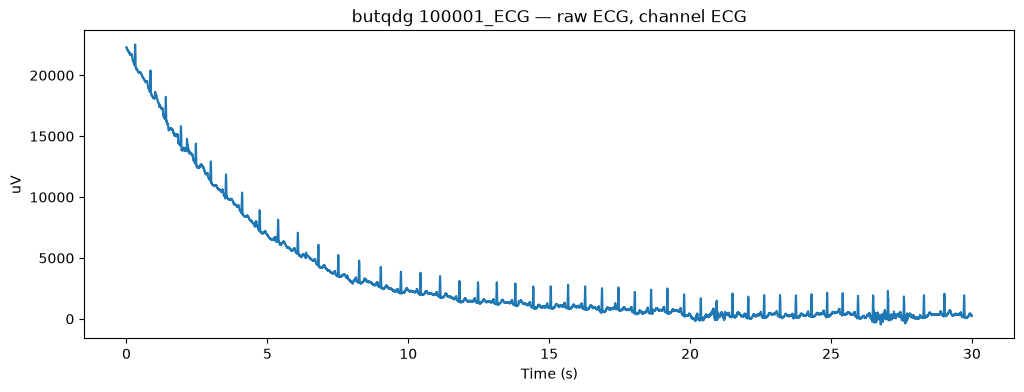

In [14]:
duration_s = 30
startpoint_s = 0
n = int(duration_s * fs)
n_start = int(startpoint_s* fs)

plt.plot(t[n_start:n], ecg[n_start:n])
plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title(f"butqdg {record_name} — raw ECG, channel {record.sig_name[0]}")
plt.show()

## 5. What does each quality class look like?

Plots 10 seconds of ECG from one segment of each class, so we can see the difference with our own eyes.
Class 1 should show clear heartbeats, class 2 heartbeats with noise, class 3 mostly noise.

In [24]:

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, q in zip(axes, [1, 2, 3]):
    seg = labels[(labels["quality"] == q) & (labels["minutes"] >= 1)].iloc[0]
    ecg, acc, _ = load_record(seg["record"], start_min=(seg["start"] - 1) / 60000, minutes=10 / 60)
    t = np.arange(ecg.sig_len) / ecg.fs
    ax.plot(t, ecg.p_signal[:, 0] / 1000, lw=0.6)
    ax.set_title(f"Quality class {q}  (record {seg['record']})", loc="left")
    ax.set_ylabel("ECG (mV)")
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

NameError: name 'records' is not defined

## Use neurokit2 on first ecg

In [15]:
signals, info = nk.ecg_process(
    ecg,
    sampling_rate=fs
)

print(signals.shape)
print(type(signals))
print(type(info))
print(signals.columns.tolist())

signals[["ECG_Raw", "ECG_Clean", "ECG_Rate", "ECG_Quality", "ECG_R_Peaks"]].head(10)

(40000, 19)
<class 'pandas.core.frame.DataFrame'>
<class 'dict'>
['ECG_Raw', 'ECG_Clean', 'ECG_Rate', 'ECG_Quality', 'ECG_R_Peaks', 'ECG_P_Peaks', 'ECG_P_Onsets', 'ECG_P_Offsets', 'ECG_Q_Peaks', 'ECG_R_Onsets', 'ECG_R_Offsets', 'ECG_S_Peaks', 'ECG_T_Peaks', 'ECG_T_Onsets', 'ECG_T_Offsets', 'ECG_Phase_Atrial', 'ECG_Phase_Completion_Atrial', 'ECG_Phase_Ventricular', 'ECG_Phase_Completion_Ventricular']


,ECG_Raw,ECG_Clean,ECG_Rate,ECG_Quality,ECG_R_Peaks
0,22290.581162,365.237373,98.106844,0.033946,0
1,22279.559118,361.028483,98.106844,0.033946,0
2,22280.561122,356.857574,98.106844,0.033946,0
3,22287.575150,352.682446,98.106844,0.033946,0
4,22290.581162,348.460877,98.106844,0.033946,0
5,22284.569138,344.200728,98.106844,0.033946,0
6,22264.529058,339.897309,98.106844,0.033946,0
7,22246.993988,335.580983,98.106844,0.033946,0
8,22234.969940,331.312152,98.106844,0.033946,0
9,22223.947896,327.111114,98.106844,0.033946,0


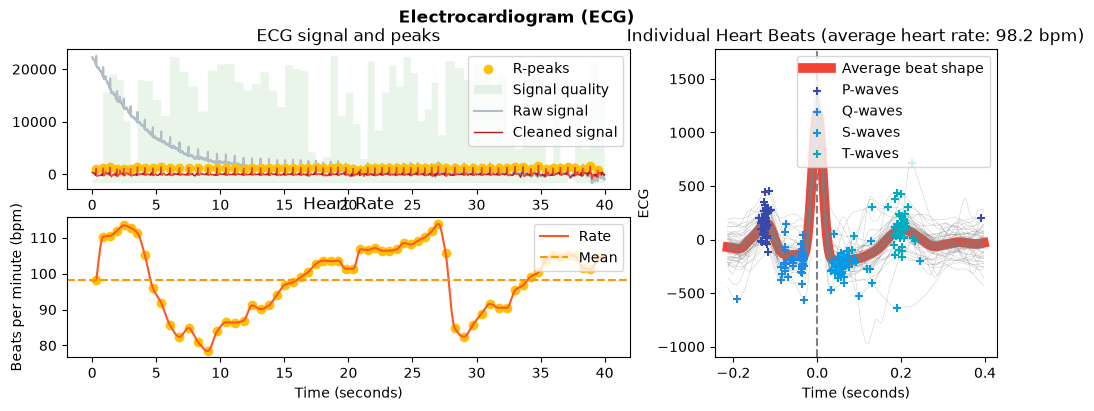

In [16]:
nk.ecg_plot(signals, info)
plt.show()

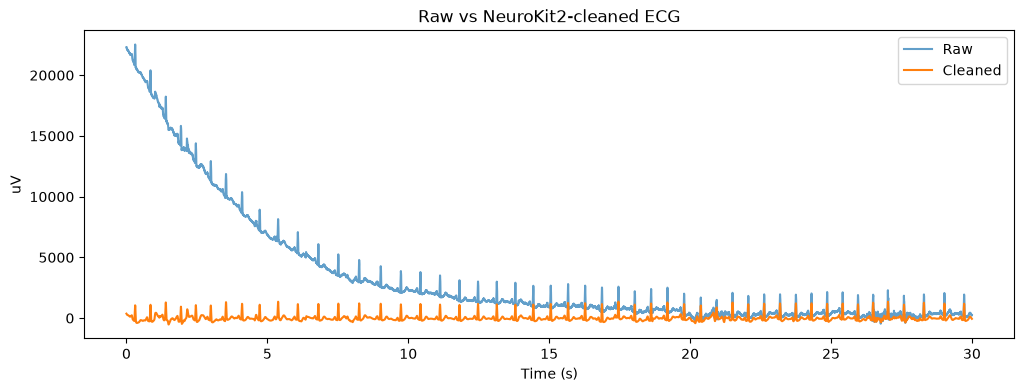

In [17]:
plt.plot(t[n_start:n], signals["ECG_Raw"].iloc[n_start:n], label="Raw", alpha=0.7)
plt.plot(t[n_start:n], signals["ECG_Clean"].iloc[n_start:n], label="Cleaned")
plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title("Raw vs NeuroKit2-cleaned ECG")
plt.legend()
plt.show()

In [19]:
rpeaks = np.asarray(info["ECG_R_Peaks"])

print("Detected R-peaks:", len(rpeaks))
print("First 10 samples:", rpeaks[:10])
print("First 10 times (s):", np.round(rpeaks[:10] / fs, 3))

Detected R-peaks: 65
First 10 samples: [ 310  854 1397 1933 2462 2994 3533 4103 4728 5381]
First 10 times (s): [0.31  0.854 1.397 1.933 2.462 2.994 3.533 4.103 4.728 5.381]


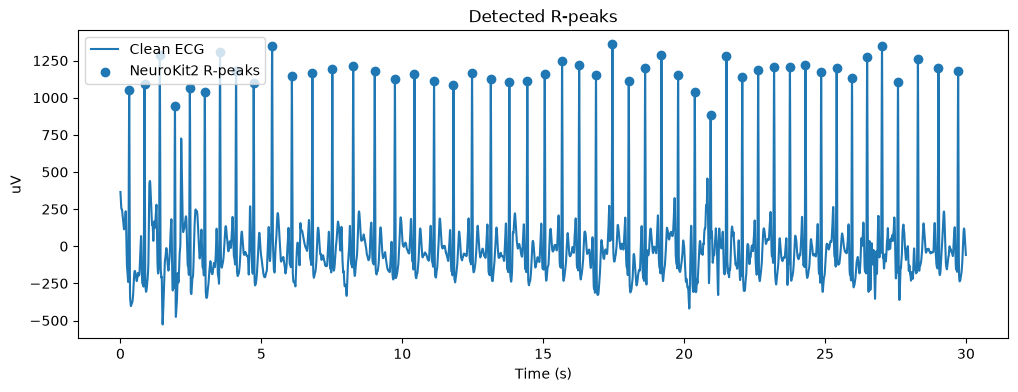

In [20]:
r_show = rpeaks[rpeaks < n]

plt.plot(t[:n], signals["ECG_Clean"].iloc[:n], label="Clean ECG")
plt.scatter(
    r_show / fs,
    signals["ECG_Clean"].to_numpy()[r_show],
    marker="o",
    label="NeuroKit2 R-peaks"
)

plt.xlabel("Time (s)")
plt.ylabel(record.units[0])
plt.title("Detected R-peaks")
plt.legend()
plt.show()


